# SemRel2024: complete human-source cohort

This audit uses all published rows from nine languages whose primary collection descriptions support real source text and human ratings. Five languages supply training pairs; four provide cross-lingual development/test evaluation only. The official shared task has 14 languages: the five mixed generated/translated-source collections are outside this authentic-text cohort.

Only aggregate counts, distributions and source checks are displayed. Test text is used for pair-copy and sentence-component checks; numeric test ratings are never loaded here.

In [1]:
from pathlib import Path
import sys, json, hashlib, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
PROCESSED=ROOT/'data/processed/semrel-full-v3'
RAW=ROOT/'data/raw/semrel-full-v3'
FIGURES=ROOT/'assets/figures'; FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
coverage=json.loads((ROOT/'docs/full-cohort-v3-coverage.json').read_text(encoding='utf-8'))
audit=json.loads((PROCESSED/'audit.json').read_text(encoding='utf-8'))
LANGUAGES=tuple(coverage['included_languages'])
TRAIN_LANGUAGES=tuple(coverage['official_train_languages'])
splits={split:[json.loads(line) for line in (PROCESSED/(split+'.jsonl')).read_text(encoding='utf-8').splitlines()] for split in ('train','dev','test')}
assert len(LANGUAGES)==9 and len(TRAIN_LANGUAGES)==5
assert all(set(row)=={'id','language','sentence1','sentence2'} for row in splits['test'])

## Source identity and complete split coverage

Checksums verify the pinned 23 official CSVs without parsing their test scores. The prepared files retain every test pair. Text-only guards remove duplicate/protected training pairs and development copies of test pairs; the table separates these removals from missing official training splits.

,official_train,train,official_dev,dev,test,removed_train,removed_dev
language,,,,,,,
afr,0,0,375,375,375,0,0
amh,992,992,95,95,171,0,0
arb,0,0,32,32,595,0,0
arq,1261,1260,97,97,583,1,0
ary,924,924,71,71,426,0,0
hau,1736,1736,212,212,603,0,0
ind,0,0,144,144,360,0,0
kin,778,728,102,79,222,50,23
pan,0,0,242,242,634,0,0


{'source_revision': '3c5941ddffdc9d833a5528f49dd13ed9087c0dba', 'official_CSVs_verified': 23, 'official_rows': {'train': 5691, 'dev': 1370, 'test': 3969}, 'prepared_rows': {'train': 5640, 'dev': 1347, 'test': 3969}, 'test_targets_loaded': False}


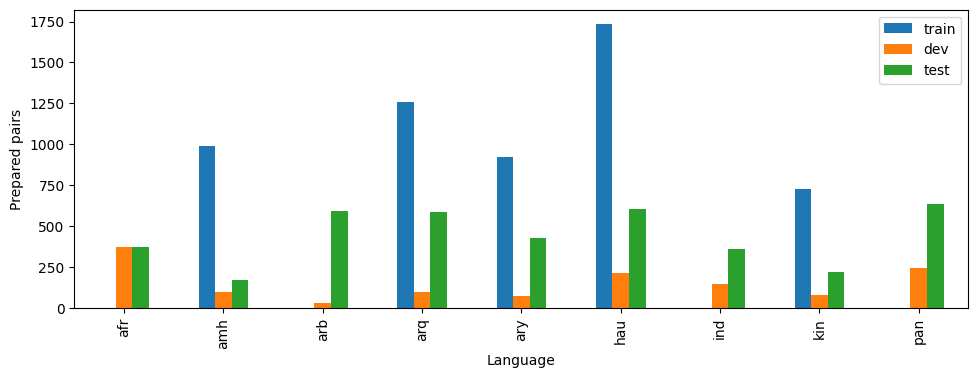

In [2]:
source_checks=[]
for key,contract in coverage['files'].items():
    path=RAW/Path(contract['path']).name
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest==contract['sha256']
    source_checks.append({'source':key,'official_pairs':contract['rows'],'checksum_verified':digest==contract['sha256']})
for split,digest in audit['processed_sha256'].items():
    assert hashlib.sha256((PROCESSED/(split+'.jsonl')).read_bytes()).hexdigest()==digest
counts=pd.DataFrame([{'language':lang,'official_train':audit['languages'][lang]['official']['train'],'train':audit['languages'][lang]['prepared']['train'],'official_dev':audit['languages'][lang]['official']['dev'],'dev':audit['languages'][lang]['prepared']['dev'],'test':audit['languages'][lang]['prepared']['test'],'removed_train':audit['languages'][lang]['removed_training_duplicates_or_protected_pairs'],'removed_dev':audit['languages'][lang]['removed_development_pairs_duplicating_test']} for lang in LANGUAGES]).set_index('language')
display(counts)
print({'source_revision':coverage['revision'],'official_CSVs_verified':len(source_checks),'official_rows':{s:sum(a['official'][s] for a in audit['languages'].values()) for s in splits},'prepared_rows':{s:len(rows) for s,rows in splits.items()},'test_targets_loaded':False})
assert counts['test'].sum()==3969 and all(a['test_unchanged'] for a in audit['languages'].values())
fig,ax=plt.subplots(figsize=(10,4));counts[['train','dev','test']].plot.bar(ax=ax)
ax.set(xlabel='Language',ylabel='Prepared pairs');show(fig,'sts_complete_cohort_counts.png')

In [3]:
from src.data.make_dataset import pair_key
for lang in LANGUAGES:
    keys={s:{pair_key(row) for row in rows if row['language']==lang} for s,rows in splits.items()}
    assert keys['train'].isdisjoint(keys['dev']|keys['test'])
    assert keys['dev'].isdisjoint(keys['test'])
print('No cross-split normalized pair copies remain; individual sentences may still repeat.')
display(pd.DataFrame([{'language':lang,'training_available':lang in TRAIN_LANGUAGES,'evaluation_only':lang not in TRAIN_LANGUAGES} for lang in LANGUAGES]))

No cross-split normalized pair copies remain; individual sentences may still repeat.


,language,training_available,evaluation_only
0,afr,False,True
1,amh,True,False
2,arb,False,True
3,arq,True,False
4,ary,True,False
5,hau,True,False
6,ind,False,True
7,kin,True,False
8,pan,False,True


## Human ratings and training balance

Rating histograms use training/development only. The five-language training objective equalizes each language's total loss weight rather than resampling or inventing pairs. Evaluation-only languages contribute no training labels.

,language,training_pairs,total_loss_weight
0,amh,992,1127.999878
1,arq,1260,1128.000000
2,ary,924,1128.000000
3,hau,1736,1128.000122
4,kin,728,1128.000000


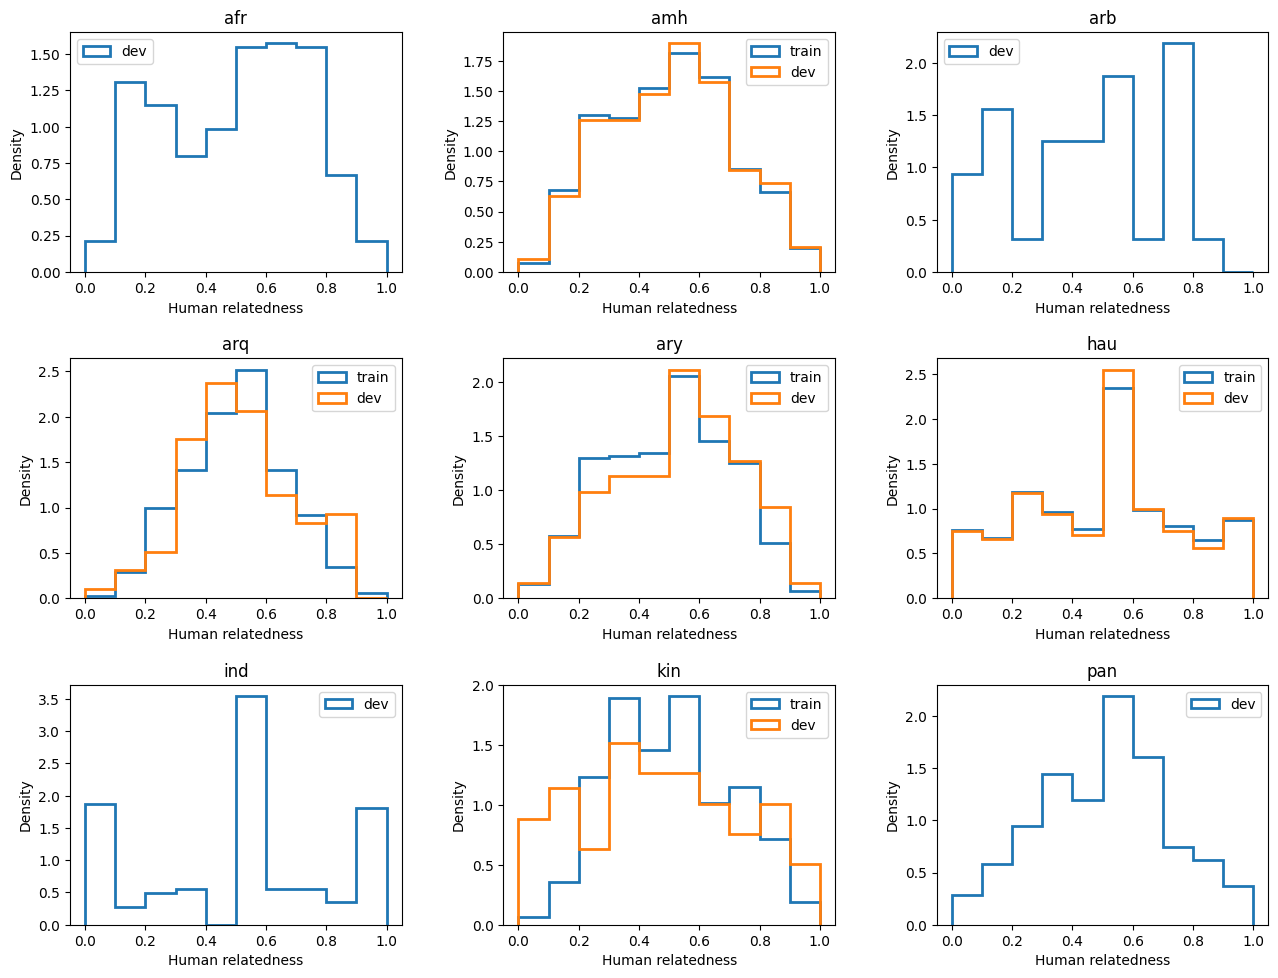

In [4]:
train_languages=np.asarray([row['language'] for row in splits['train']])
weights=np.asarray([len(train_languages)/(len(TRAIN_LANGUAGES)*(train_languages==lang).sum()) for lang in train_languages],np.float32)
display(pd.DataFrame([{'language':lang,'training_pairs':int((train_languages==lang).sum()),'total_loss_weight':float(weights[train_languages==lang].sum())} for lang in TRAIN_LANGUAGES]))
assert np.allclose([weights[train_languages==lang].sum() for lang in TRAIN_LANGUAGES],len(train_languages)/5)
fig,axes=plt.subplots(3,3,figsize=(13,10))
for ax,lang in zip(axes.flat,LANGUAGES):
    for split in ('train','dev'):
        values=[row['target'] for row in splits[split] if row['language']==lang]
        if values:ax.hist(values,bins=np.linspace(0,1,11),density=True,histtype='step',linewidth=2,label=split)
    ax.set(title=lang,xlabel='Human relatedness',ylabel='Density');ax.legend()
show(fig,'sts_rating_distributions.png')

## Text lengths and scripts

Whitespace counts are a descriptive text statistic, not encoder token counts. Unicode letter names provide a label-free check that evaluation-only scripts, including Punjabi's Gurmukhi, are represented. Encoder truncation is checked separately from actual cached tokenization.

sentences  median_characters  p95_characters  \
language split                                                 
afr      dev          750               80.0          115.00   
amh      dev          190               34.5           69.65   
         train       1984               37.0           67.00   
arb      dev           64               39.5          108.85   
arq      dev          194               28.0           54.35   
         train       2520               29.0           66.00   
ary      dev          142               92.0          199.00   
         train       1848               97.0          214.00   
hau      dev          424              109.0          144.85   
         train       3472              108.0          143.00   
ind      dev          288               85.0          115.00   
kin      dev          158              140.5          189.15   
         train       1456              144.0          190.00   
pan      dev          484               94.0          126.00   

                median_whitespace_tokens  
language split                            
afr      dev                        14.0  
amh      dev                         8.0  
         train                       9.0  
arb      dev                         7.0  
arq      dev                         6.0  
         train                       6.0  
ary      dev                        15.0  
         train                      16.0  
hau      dev                        20.0  
         train                      20.0  
ind      dev                        13.0  
kin      dev                        20.0  
         train                      21.0  
pan      dev                        19.0

,language,alphabetic_characters,leading_Unicode_name,leading_fraction
0,afr,48542,LATIN,1.000000
1,amh,5196,ETHIOPIC,1.000000
2,arb,2345,ARABIC,0.999574
3,arq,4718,ARABIC,1.000000
4,ary,11548,ARABIC,0.999740
5,hau,35629,LATIN,1.000000
6,ind,19129,LATIN,0.999164
7,kin,18013,LATIN,1.000000
8,pan,21269,GURMUKHI,0.999248


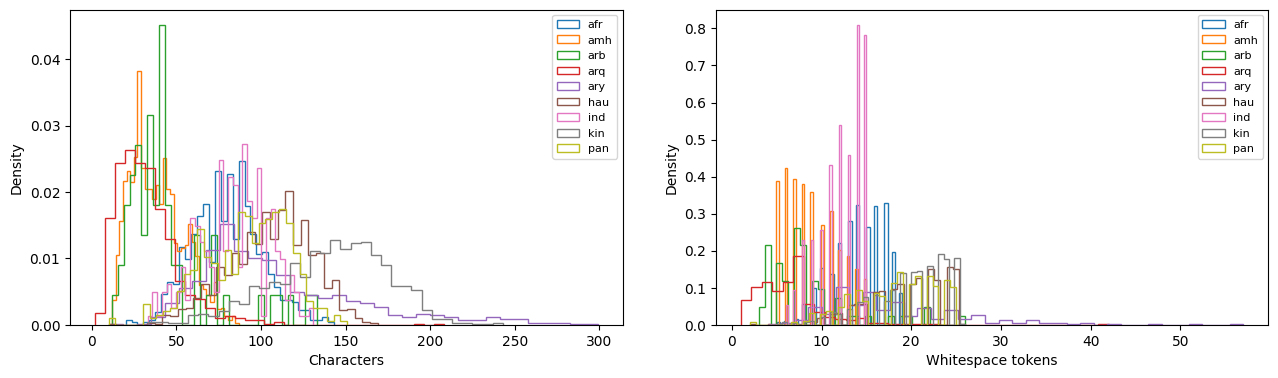

In [5]:
lengths=pd.DataFrame([{'language':row['language'],'split':split,'characters':len(row[key]),'whitespace_tokens':len(row[key].split())} for split in ('train','dev') for row in splits[split] for key in ('sentence1','sentence2')])
display(lengths.groupby(['language','split']).agg(sentences=('characters','size'),median_characters=('characters','median'),p95_characters=('characters',lambda x:x.quantile(.95)),median_whitespace_tokens=('whitespace_tokens','median')))
script_rows=[]
for lang in LANGUAGES:
    letters=[c for row in splits['dev'] if row['language']==lang for key in ('sentence1','sentence2') for c in row[key] if c.isalpha()]
    names=pd.Series([unicodedata.name(c,'UNNAMED').split()[0] for c in letters]).value_counts()
    script_rows.append({'language':lang,'alphabetic_characters':len(letters),'leading_Unicode_name':names.index[0],'leading_fraction':float(names.iloc[0]/len(letters))})
display(pd.DataFrame(script_rows))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for lang,block in lengths.groupby('language'):
    axes[0].hist(block['characters'],bins=35,histtype='step',density=True,label=lang)
    axes[1].hist(block['whitespace_tokens'],bins=35,histtype='step',density=True,label=lang)
axes[0].set(xlabel='Characters',ylabel='Density');axes[1].set(xlabel='Whitespace tokens',ylabel='Density')
for ax in axes:ax.legend(fontsize=8)
show(fig,'sts_text_length_audit.png')

## Sentence-connected components

Pair-copy removal does not make official evaluation sentence-disjoint. This audit joins pairs through shared normalized sentences across all splits, without consulting test labels. Large connected groups motivate component-aware uncertainty and limit claims of independent-document transfer.

,components,sentence_nodes,largest_component_sentence_nodes,cross_split_components
amh,1240,2498,4,6
arq,1415,3353,8,195
ary,844,2132,13,178
hau,403,2753,1364,131
kin,826,1851,10,72
afr,666,1414,7,38
arb,618,1245,7,1
ind,439,937,5,25
pan,428,1243,26,97


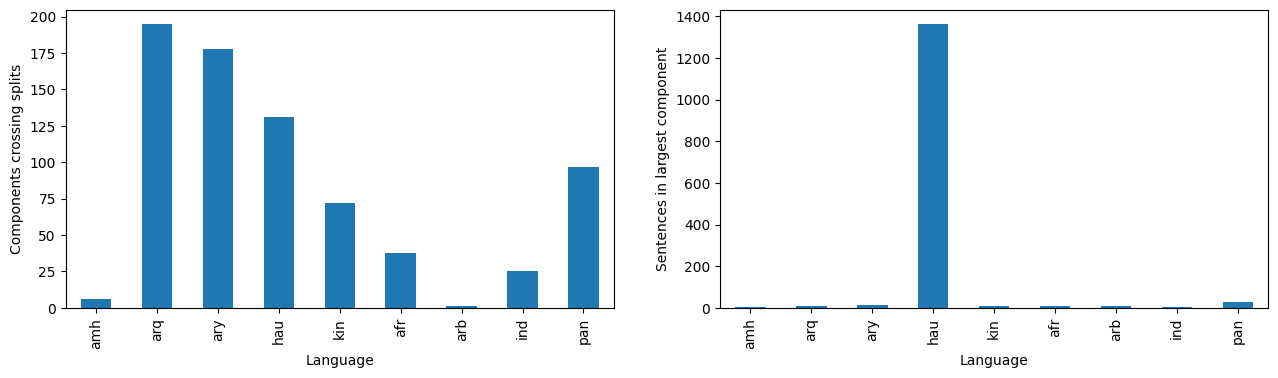

{'component_audit_uses_test_targets': False, 'prepared_test_rows_unchanged': 3969, 'previously_observed_test_languages': ['amh', 'hau', 'kin']}


In [6]:
from src.data.components import audit_components
groups,component_audit=audit_components(splits)
components=pd.DataFrame(component_audit['languages']).T
display(components[['components','sentence_nodes','largest_component_sentence_nodes','cross_split_components']])
fig,axes=plt.subplots(1,2,figsize=(13,4))
components['cross_split_components'].plot.bar(ax=axes[0]);axes[0].set(xlabel='Language',ylabel='Components crossing splits')
components['largest_component_sentence_nodes'].plot.bar(ax=axes[1]);axes[1].set(xlabel='Language',ylabel='Sentences in largest component')
show(fig,'sts_sentence_component_audit.png')
print({'component_audit_uses_test_targets':component_audit['label_access'],'prepared_test_rows_unchanged':3969,'previously_observed_test_languages':audit['previously_observed_test_languages']})

All nine compatible languages and all available official splits are included. This is not the entire 14-language shared task. The Amharic, Hausa and Kinyarwanda tests were previously observed; the expanded pooled score must not be presented as wholly untouched. Upstream encoder exposure to source text is unknown.